# 07 · Comparing the four models and analysing their errors

Uses the validation predictions saved by notebooks 02–05 (each model's best configuration).
Questions answered here:
* the required results table (validation accuracy of every method on both tasks)
* per-class precision / recall / F1, and whether **Neutral** is harder than Negative / Positive
* which **image classes** are most confused, and whether the models struggle on the same classes
* whether the models make the **same mistakes**, and whether the neural network fixes the simpler models' mistakes
* training / prediction time

In [1]:
import sys
import json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, f1_score  # metrics only
from src.common import *
from src.plotting import *

MODELS = {"knn": "k-NN", "dt": "Decision Tree", "rf": "Random Forest", "nn": "Neural Network"}
TASKS = ("image", "sentiment")
y_val = {t: get_split(t)[3] for t in TASKS}
pred, proba, info = {}, {}, {}
for t in TASKS:
    for m in MODELS:
        d = np.load(PRED_DIR / f"{t}_{m}.npz")
        pred[(t, m)], proba[(t, m)] = d["y_pred"], d["proba"]
        info[(t, m)] = json.load(open(PRED_DIR / f"{t}_{m}.json"))

## 1 · Results table (validation accuracy)

In [2]:
rows = []
for m, name in MODELS.items():
    r = dict(Method=name)
    for t in TASKS:
        r[f"{t} val acc"] = accuracy(y_val[t], pred[(t, m)])
        r[f"{t} macro-F1"] = f1_score(y_val[t], pred[(t, m)], average="macro")
    r["average of the two accuracies"] = (r["image val acc"] + r["sentiment val acc"]) / 2
    rows.append(r)
results = pd.DataFrame(rows)
save_table(results, "summary_validation")
results.round(4)

,Method,image val acc,image macro-F1,sentiment val acc,sentiment macro-F1,average of the two accuracies
0,k-NN,0.5805,0.5824,0.5933,0.5788,0.5869
1,Decision Tree,0.1192,0.1108,0.4896,0.4882,0.3044
2,Random Forest,0.3662,0.3497,0.6029,0.6007,0.4846
3,Neural Network,0.3915,0.3895,0.6829,0.6779,0.5372


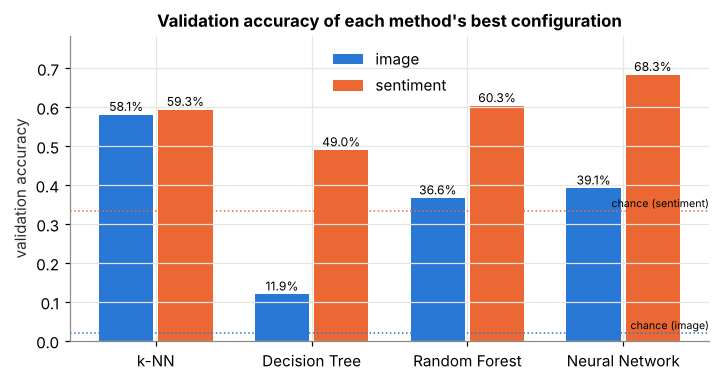

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(MODELS)); w = 0.38
for j, t in enumerate(TASKS):
    vals = results[f"{t} val acc"].to_numpy()
    bars = ax.bar(x + (j - 0.5) * w, vals, width=w - 0.03, color=PALETTE[j], label=t)
    for xi, v in zip(x + (j - 0.5) * w, vals):
        ax.text(xi, v + 0.01, f"{v:.1%}", ha="center", fontsize=8)
ax.axhline(1 / 50, color=PALETTE[0], linestyle=":", linewidth=1)
ax.axhline(1 / 3, color=PALETTE[1], linestyle=":", linewidth=1)
ax.text(3.55, 1 / 50 + 0.01, "chance (image)", fontsize=7, ha="right")
ax.text(3.55, 1 / 3 + 0.01, "chance (sentiment)", fontsize=7, ha="right")
ax.set_xticks(x); ax.set_xticklabels(MODELS.values()); ax.set_ylabel("validation accuracy")
ax.set_ylim(0, max(results[["image val acc", "sentiment val acc"]].max()) + 0.1)
ax.set_title("Validation accuracy of each method's best configuration"); ax.legend()
savefig(fig, "07_summary_accuracy"); plt.show()

**The ranking flips between tasks.**
* Images: **k-NN 58.1%** ≫ Neural Network 39.1% > Random Forest 36.6% ≫ Decision Tree 11.9% (chance 2%).
* Sentiment: **Neural Network 68.3%** > Random Forest 60.3% ≈ k-NN 59.3% ≫ Decision Tree 49.0% (chance 33%).

The best algorithm on one representation is not the best on the other. k-NN wins on the image
histograms because each class is made of small groups of near-relatives (notebook 02). The network
wins on BERT embeddings, where sentiment is spread thinly over many dimensions and a learned
combination of all features beats voting among neighbours. The Decision Tree is last on both: one
feature per question is a poor fit for both kinds of features.

These are the best configurations found *on this validation set*, so they are slightly optimistic. For
the network, the 5-seed means are 38.8% (image) and 68.0% (sentiment). Differences under ~1% are noise.

## 2 · Sentiment: is Neutral the hardest class?

In [4]:
rows = []
for m, name in MODELS.items():
    p, r, f, s = precision_recall_fscore_support(y_val["sentiment"], pred[("sentiment", m)], labels=[0, 1, 2])
    for c in range(3):
        rows.append(dict(model=name, cls=SENTIMENT_NAMES[c], precision=p[c], recall=r[c], f1=f[c]))
sent_cls = pd.DataFrame(rows)
save_table(sent_cls, "sentiment_per_class")
sent_cls.pivot(index="model", columns="cls", values="f1")[SENTIMENT_NAMES].loc[list(MODELS.values())].round(3)

cls,Negative,Neutral,Positive
model,,,
k-NN,0.660,0.449,0.627
Decision Tree,0.557,0.448,0.460
Random Forest,0.663,0.527,0.612
Neural Network,0.746,0.580,0.708


In [5]:
sent_cls.round(3)

,model,cls,precision,recall,f1
0,k-NN,Negative,0.590,0.749,0.660
1,k-NN,Neutral,0.626,0.350,0.449
2,k-NN,Positive,0.581,0.681,0.627
3,Decision Tree,Negative,0.533,0.582,0.557
4,Decision Tree,Neutral,0.440,0.456,0.448
5,Decision Tree,Positive,0.494,0.430,0.460
6,Random Forest,Negative,0.625,0.705,0.663
7,Random Forest,Neutral,0.550,0.506,0.527
8,Random Forest,Positive,0.628,0.598,0.612
9,Neural Network,Negative,0.693,0.809,0.746


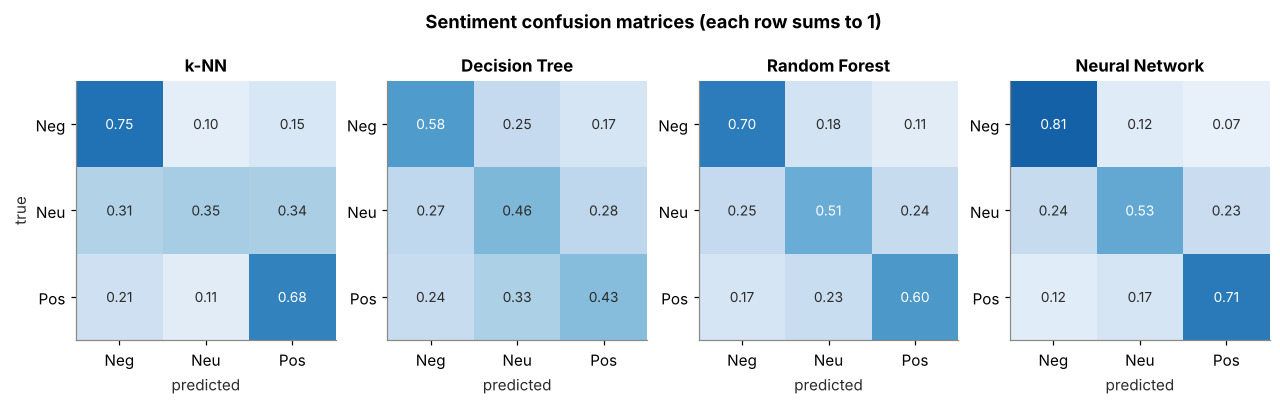

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (m, name) in zip(axes, MODELS.items()):
    cm = confusion_matrix(y_val["sentiment"], pred[("sentiment", m)], labels=[0, 1, 2])
    frac = cm / cm.sum(1, keepdims=True)
    ax.imshow(frac, cmap=SEQ_CMAP, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{frac[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if frac[i, j] > .5 else "#2b2b2a")
    ax.set_xticks(range(3)); ax.set_xticklabels(["Neg", "Neu", "Pos"])
    ax.set_yticks(range(3)); ax.set_yticklabels(["Neg", "Neu", "Pos"])
    ax.set_xlabel("predicted"); ax.set_title(name); ax.grid(False)
axes[0].set_ylabel("true")
fig.suptitle("Sentiment confusion matrices (each row sums to 1)", y=1.03, fontweight="bold")
savefig(fig, "07_sentiment_confusion"); plt.show()

**Yes: Neutral is the hardest class for every model** (F1 0.45–0.58, vs 0.56–0.75 for Negative and
0.46–0.71 for Positive). Negative is the easiest. Most errors involve Neutral: the network
mislabels 24% of Neutral tweets as Negative and 23% as Positive, while Negative→Positive mistakes are
rarer (7%). k-NN is especially bad at Neutral (recall 35%: it predicts Neutral for only 447 of 2,400
tweets). Neutral tweets sit *between* the other two (notebook 01), so a neutral tweet's neighbours
are often mostly negative or mostly positive. All models also lean towards predicting Negative.

## 3 · Images: which classes are hard, and which get confused?

In [7]:
per_class = pd.DataFrame({name: [np.mean(pred[("image", m)][y_val["image"] == c] == c) for c in range(50)]
                          for m, name in MODELS.items()})
per_class.index.name = "class"
save_table(per_class.reset_index(), "image_per_class_accuracy")
best_img = results.sort_values("image val acc").iloc[-1].Method
print("best image model:", best_img)
order = per_class[best_img].sort_values()
print("\nhardest classes for", best_img); print(per_class.loc[order.index[:6]].round(2))
print("\neasiest classes for", best_img); print(per_class.loc[order.index[-6:]].round(2))
print("\nDo the models find the same classes hard? Correlation of per-class accuracy between models:")
print(per_class.corr(method="spearman").round(2))

best image model: k-NN

hardest classes for k-NN
       k-NN  Decision Tree  Random Forest  Neural Network
class                                                    
22     0.34           0.02           0.08            0.25
27     0.40           0.01           0.18            0.31
40     0.41           0.05           0.16            0.26
9      0.42           0.01           0.19            0.18
29     0.42           0.05           0.15            0.24
14     0.44           0.04           0.29            0.36

easiest classes for k-NN
       k-NN  Decision Tree  Random Forest  Neural Network
class                                                    
25     0.75           0.24           0.70            0.62
32     0.75           0.16           0.59            0.50
5      0.80           0.50           0.76            0.74
13     0.81           0.26           0.69            0.61
48     0.82           0.36           0.70            0.65
46     0.84           0.52           0.69            0.

In [8]:
def top_confused(m, n=10):
    cm = confusion_matrix(y_val["image"], pred[("image", m)], labels=range(50)).astype(float)
    sym = cm + cm.T
    iu = np.triu_indices(50, k=1)
    df = pd.DataFrame(dict(class_a=iu[0], class_b=iu[1], confusions=sym[iu].astype(int),
                           a_as_b=cm[iu].astype(int), b_as_a=cm.T[iu].astype(int)))
    return df.sort_values("confusions", ascending=False).head(n)

key = {v: k for k, v in MODELS.items()}[best_img]
conf = top_confused(key, 15)
# Do the other models (and k-Means) also mix these pairs up?
pair_sets = {name: set(map(tuple, top_confused(m, 30)[["class_a", "class_b"]].to_numpy())) for m, name in MODELS.items()}
km_pairs = pd.read_csv(TABLES_DIR / "kmeans_image_coclustered_pairs.csv")
km_top = set(map(tuple, km_pairs.head(30)[["class_a", "class_b"]].to_numpy()))
for name in MODELS.values():
    if name != best_img:
        conf[f"in {name} top-30"] = [(a, b) in pair_sets[name] for a, b in zip(conf.class_a, conf.class_b)]
conf["in k-Means top-30 co-clustered"] = [(a, b) in km_top for a, b in zip(conf.class_a, conf.class_b)]
save_table(conf, "image_most_confused_pairs")
print(f"most confused class pairs for {best_img} (out of 80 validation images per class):")
conf

most confused class pairs for k-NN (out of 80 validation images per class):


,class_a,class_b,confusions,a_as_b,b_as_a,in Decision Tree top-30,in Random Forest top-30,in Neural Network top-30,in k-Means top-30 co-clustered
98,2,4,15,1,14,True,True,True,True
97,2,3,12,1,11,True,True,True,True
1148,37,39,12,6,6,True,True,True,True
322,7,8,11,9,2,False,True,True,True
523,12,14,10,2,8,True,True,False,True
619,14,39,10,6,4,False,True,False,False
595,14,15,10,3,7,True,False,False,False
49,1,2,10,8,2,False,False,True,False
1159,38,39,9,6,3,False,False,False,False
570,13,25,9,4,5,True,False,False,False


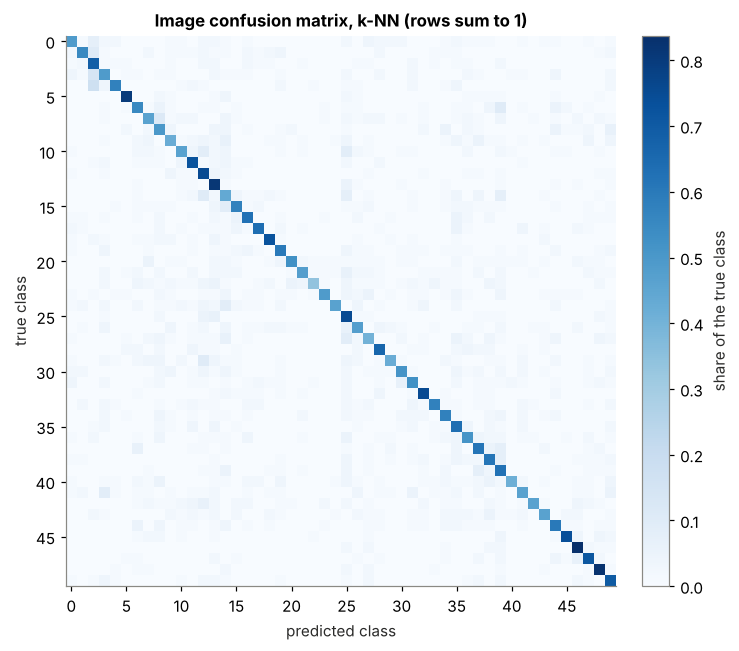

In [9]:
cm = confusion_matrix(y_val["image"], pred[("image", key)], labels=range(50))
frac = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(frac, cmap=SEQ_CMAP, vmin=0, vmax=frac.max())
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.grid(False)
ax.set_xticks(range(0, 50, 5)); ax.set_yticks(range(0, 50, 5))
ax.set_title(f"Image confusion matrix, {best_img} (rows sum to 1)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="share of the true class")
savefig(fig, "07_image_confusion"); plt.show()

* **The models agree on which classes are hard** (rank correlation of per-class accuracy 0.63–0.86).
  Hardest for k-NN: classes 22, 27, 40, 9, 29 (34–42%); easiest: 46, 48, 13, 5 (80–84%). We only
  have class numbers, not object names.
* **Confusions are often one-directional**: class 4 is predicted as class 2 fourteen times, but 2 as 4
  only once, and 3 → 2 eleven times. Class 2 acts as a "hub" that attracts neighbours from similar classes.
* **The most-confused pairs are genuinely close in feature space**: the top five k-NN pairs are all
  among k-Means' 30 most co-clustered pairs (notebook 06), and the top four are confused by the
  Random Forest and the network too.

## 4 · Do the models make the same mistakes?

In [10]:
for t in TASKS:
    E = pd.DataFrame({name: pred[(t, m)] != y_val[t] for m, name in MODELS.items()})
    n_wrong = E.sum(axis=1)
    print(f"\n=== {t} === ({len(E)} validation examples)")
    print("  all 4 models right: %5.1f%%" % (100 * (n_wrong == 0).mean()))
    print("  all 4 models wrong: %5.1f%%" % (100 * (n_wrong == 4).mean()))
    print("  exactly one right:  %5.1f%%" % (100 * (n_wrong == 3).mean()))
    print("  if all 4 were independent, 'all wrong' would be %.1f%%" % (100 * np.prod(E.mean())))
    # P(column wrong | row wrong)
    cond = pd.DataFrame({b: [E.loc[E[a], b].mean() for a in E] for b in E}, index=E.columns)
    print("  P(column model wrong | row model wrong):")
    print(cond.round(2).to_string())
    save_table(cond.reset_index().rename(columns={"index": "given_wrong"}), f"{t}_conditional_errors")


=== image === (4000 validation examples)
  all 4 models right:   7.4%
  all 4 models wrong:  30.5%
  exactly one right:   25.2%
  if all 4 were independent, 'all wrong' would be 14.2%
  P(column model wrong | row model wrong):
                k-NN  Decision Tree  Random Forest  Neural Network
k-NN            1.00           0.95           0.87            0.82
Decision Tree   0.45           1.00           0.69            0.65
Random Forest   0.57           0.96           1.00            0.77
Neural Network  0.57           0.95           0.81            1.00

=== sentiment === (2400 validation examples)
  all 4 models right:  29.9%
  all 4 models wrong:  15.0%
  exactly one right:   15.8%
  if all 4 were independent, 'all wrong' would be 2.6%
  P(column model wrong | row model wrong):
                k-NN  Decision Tree  Random Forest  Neural Network
k-NN            1.00           0.66           0.73            0.59
Decision Tree   0.53           1.00           0.55            0.41
Rando

**Largely yes, the mistakes are shared.** On images, 30.5% of validation examples are missed by all
four models, twice the 14.2% we would expect if their errors were independent. On sentiment, 15.0% are
missed by all four vs 2.6% expected. Some examples are hard for *any* model on these features
(ambiguous tweets, unusual photos). That also limits what ensembling can achieve.

### Does the neural network fix the simpler models' mistakes?

In [11]:
rows = []
for t in TASKS:
    nn_right = pred[(t, "nn")] == y_val[t]
    for m in ("knn", "dt", "rf"):
        wrong = pred[(t, m)] != y_val[t]
        rows.append(dict(task=t, simpler_model=MODELS[m], simpler_model_errors=int(wrong.sum()),
                         nn_fixes=float(nn_right[wrong].mean()),
                         nn_breaks=float((~nn_right[~wrong]).mean())))
fix = pd.DataFrame(rows)
save_table(fix, "nn_fixes_errors")
print("nn_fixes  = share of that model's mistakes the NN gets right")
print("nn_breaks = share of that model's correct answers the NN gets wrong")
fix.round(3)

nn_fixes  = share of that model's mistakes the NN gets right
nn_breaks = share of that model's correct answers the NN gets wrong


,task,simpler_model,simpler_model_errors,nn_fixes,nn_breaks
0,image,k-NN,1678,0.176,0.453
1,image,Decision Tree,3523,0.347,0.277
2,image,Random Forest,2535,0.226,0.322
3,sentiment,k-NN,976,0.414,0.133
4,sentiment,Decision Tree,1225,0.588,0.218
5,sentiment,Random Forest,953,0.390,0.124


* **Sentiment: yes.** The network gets right 41% of k-NN's mistakes and 39% of the Random Forest's,
  while breaking only 12–13% of their correct answers. It is a real improvement, not just a reshuffle.
* **Images: no, compared with k-NN.** The network fixes only 18% of k-NN's mistakes but gets 45% of
  k-NN's correct answers wrong. The two models disagree in an unhelpful way, which is why averaging them
  (notebook 08) scores *below* k-NN alone.

## 5 · How confident is the network when it is wrong?

In [12]:
rows = []
for t in TASKS:
    p = proba[(t, "nn")]
    conf_ = p.max(1)
    right = p.argmax(1) == y_val[t]
    for lo, hi in ((0, .4), (.4, .6), (.6, .8), (.8, .95), (.95, 1.01)):
        m = (conf_ >= lo) & (conf_ < hi)
        rows.append(dict(task=t, confidence=f"{lo:.2f}–{min(hi, 1):.2f}", share_of_examples=m.mean(),
                         accuracy=right[m].mean() if m.any() else np.nan))
confidence = pd.DataFrame(rows)
save_table(confidence, "nn_confidence_bins")
confidence.round(3)

,task,confidence,share_of_examples,accuracy
0,image,0.00–0.40,0.066,0.182
1,image,0.40–0.60,0.180,0.191
2,image,0.60–0.80,0.180,0.244
3,image,0.80–0.95,0.208,0.342
4,image,0.95–1.00,0.364,0.630
5,sentiment,0.00–0.40,0.017,0.512
6,sentiment,0.40–0.60,0.274,0.539
7,sentiment,0.60–0.80,0.371,0.653
8,sentiment,0.80–0.95,0.252,0.810
9,sentiment,0.95–1.00,0.086,0.932


On sentiment, confidence is meaningful: above 0.95 the network is right 93% of the time, below 0.6
only about 54%. On images the network is **over-confident**: 36% of its predictions have confidence
≥ 0.95, but only 63% of those are right. This is a typical symptom of a network that has memorised its
training set (100% training accuracy).

## 6 · Computational cost (same machine, approximate)

In [13]:
rows = []
for t in TASKS:
    for m, name in MODELS.items():
        i = info[(t, m)]
        rows.append(dict(task=t, model=name, fit_seconds=i.get("fit_seconds"), predict_seconds_for_val=i.get("predict_seconds")))
cost = pd.DataFrame(rows)
save_table(cost, "compute_cost")
cost.round(2)

,task,model,fit_seconds,predict_seconds_for_val
0,image,k-NN,0.09,0.96
1,image,Decision Tree,3.83,0.00
2,image,Random Forest,552.12,1.37
3,image,Neural Network,94.20,0.08
4,sentiment,k-NN,0.02,0.40
5,sentiment,Decision Tree,1.51,0.00
6,sentiment,Random Forest,71.13,0.35
7,sentiment,Neural Network,27.68,0.02


Measured on a 2-core cloud machine with other jobs running, so only the order of magnitude matters.
k-NN has no training cost but pays at prediction time (distances to every training row). The Random
Forest is by far the most expensive to train (400 trees in pure NumPy). The network is moderate to
train and almost free to apply. The single tree is cheap but weak.